# ⚙️ Saudi Arabia NWP: Physics-Informed Feature Engineering Pipeline
### *Machine Learning & Deep Learning Predictor Construction*
**Source Data:** `data/raw/nwp/cams_forecast_saudi_arabia.nc`  
**Methodological Alignment:** [`SUPERVISOR_RESPONSE_METHODOLOGY_PLAN.md`](../Documentation/SUPERVISOR_RESPONSE_METHODOLOGY_PLAN.md) (Line A LightGBM & Line B PINN)

---

### 📌 Notebook Objectives
1. **Tabular & Tensor Transformation:** Flatten multi-dimensional NetCDF grids into clean, structured feature matrices.
2. **Aerodynamic Friction Velocity & Owen Saltation Features:**
   * Compute friction velocity $u_* = \kappa \frac{W_{10}}{\ln(z / z_0)}$
   * Model Owen (1964) saltation flux $F_{\text{salt}}$ with critical sand threshold $u_{*t} \approx 0.28\,\text{m}/\text{s}$.
3. **Atmospheric Dynamic & Kinetic Predictors:**
   * Kinetic energy flux ($W_{10}^3$), wind direction sine/cosine decomposition, and vorticity proxies.
4. **Column & Aerosol Optical Features:**
   * Surface-to-column ratio $\text{Dust\_Ratio} = \frac{\text{PM}_{10}}{\text{AOD}_{550} + \epsilon}$.
5. **Spatial Geography & Source Distance Encodings:**
   * Proximity to major dust sources: Rub' al Khali ($21^\circ\text{N}, 50^\circ\text{E}$) and An-Nafud ($28.5^\circ\text{N}, 42^\circ\text{E}$).
   * Proximity to major urban centers (Riyadh, Dammam, Jeddah).
6. **Feature Matrix Export:** Export engineered features to Parquet/CSV ready for Line A LightGBM training.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

nc_path = Path("../data/raw/nwp/cams_forecast_saudi_arabia.nc")
if not nc_path.exists():
    nc_path = Path("data/raw/nwp/cams_forecast_saudi_arabia.nc")

ds = xr.open_dataset(nc_path)
print(f"✅ Loaded NWP Dataset: {ds.sizes}")


✅ Loaded NWP Dataset: Frozen({'forecast_period': 9, 'forecast_reference_time': 6, 'latitude': 43, 'longitude': 56})


---
## 1.0 Grid Extraction & Base Table Construction
We convert the 4D xarray Dataset (`forecast_reference_time`, `forecast_period`, `latitude`, `longitude`) into a structured DataFrame.


In [2]:
# Convert Dataset to DataFrame
df_raw = ds[["pm10", "duaod550", "u10", "v10"]].to_dataframe().reset_index()

# Rename and format basic columns
df_features = pd.DataFrame()
df_features["ref_time"] = df_raw["forecast_reference_time"]
df_features["valid_time"] = df_raw["valid_time"]
df_features["lead_hours"] = df_raw["forecast_period"].dt.total_seconds() / 3600.0 if np.issubdtype(df_raw["forecast_period"].dtype, np.timedelta64) else df_raw["forecast_period"]
df_features["latitude"] = df_raw["latitude"]
df_features["longitude"] = df_raw["longitude"]

# Physical raw variables
df_features["nwp_pm10_ugm3"] = df_raw["pm10"] * 1e9  # Convert kg/m3 to ug/m3
df_features["nwp_aod550"] = df_raw["duaod550"]
df_features["u10"] = df_raw["u10"]
df_features["v10"] = df_raw["v10"]

print(f"Base Feature Table Created: {df_features.shape[0]:,} rows × {df_features.shape[1]} columns")
df_features.head()


Base Feature Table Created: 130,032 rows × 9 columns


,ref_time,valid_time,lead_hours,latitude,longitude,nwp_pm10_ugm3,nwp_aod550,u10,v10
0,2024-04-01,2024-04-04,72.0,32.8,34.0,50.686100,0.039361,1.841813,-0.874023
1,2024-04-01,2024-04-04,72.0,32.8,34.4,49.325951,0.033931,1.009049,-0.668945
2,2024-04-01,2024-04-04,72.0,32.8,34.8,40.433937,0.030227,0.079850,0.521240
3,2024-04-01,2024-04-04,72.0,32.8,35.2,37.535717,0.043146,0.118180,0.337402
4,2024-04-01,2024-04-04,72.0,32.8,35.6,29.219524,0.060772,-0.547835,-0.186279


---
## 2.0 Dynamic Wind & Kinetic Features
Wind velocity drives both dust detachment (saltation) and horizontal plume transport (advection). We compute:
* Total Wind Velocity: $W_{10} = \sqrt{u_{10}^2 + v_{10}^2}$
* Kinetic Energy Proxy: $E_{\text{kin}} = W_{10}^2$
* Aerodynamic Drag / Power Flux: $P_{\text{wind}} = W_{10}^3$
* Meteorological Wind Direction (Degrees from North):
  $$\theta = (270^\circ - \text{atan2}(v_{10}, u_{10}) \times 180 / \pi) \pmod{360}$$
* Directional Trigonometric Encodings: $\sin(\theta), \cos(\theta)$


In [3]:
# 1. Total Wind Speed
df_features["wind_speed_10m"] = np.sqrt(df_features["u10"]**2 + df_features["v10"]**2)

# 2. Wind Kinetic & Power Flux (cubic relation to dust emission)
df_features["wind_kinetic_energy"] = df_features["wind_speed_10m"]**2
df_features["wind_power_flux"] = df_features["wind_speed_10m"]**3

# 3. Meteorological Wind Direction
wind_dir_rad = np.arctan2(df_features["u10"], df_features["v10"])
df_features["wind_direction_deg"] = (np.degrees(wind_dir_rad) + 360) % 360
df_features["wind_dir_sin"] = np.sin(wind_dir_rad)
df_features["wind_dir_cos"] = np.cos(wind_dir_rad)

# 4. Wind Gust Risk Categorization
df_features["is_gale_wind"] = (df_features["wind_speed_10m"] >= 10.8).astype(int) # Beaufort scale 6+

print("✅ Wind dynamic features engineered successfully!")
df_features[["wind_speed_10m", "wind_kinetic_energy", "wind_power_flux", "wind_direction_deg"]].describe()


✅ Wind dynamic features engineered successfully!


,wind_speed_10m,wind_kinetic_energy,wind_power_flux,wind_direction_deg
count,130032.000000,130032.000000,1.300320e+05,130032.000000
mean,3.362060,14.251259,7.066525e+01,178.566360
std,1.716925,13.865859,1.065147e+02,105.992691
min,0.006331,0.000040,2.537681e-07,0.000275
25%,2.082434,4.336530,9.030537e+00,81.335670
50%,3.218210,10.356873,3.333059e+01,180.157181
75%,4.430100,19.625790,8.694422e+01,268.231522
max,11.575713,133.997131,1.551112e+03,359.999634


---
## 3.0 Physics-Informed Owen Saltation & Friction Velocity Features
Following Section 2.1 of [`SUPERVISOR_RESPONSE_METHODOLOGY_PLAN.md`](../Documentation/SUPERVISOR_RESPONSE_METHODOLOGY_PLAN.md):
* **Friction Velocity ($u_*$):**
  $$u_* = \frac{\kappa \cdot W_{10}}{\ln(z / z_0)}$$
  where $\kappa = 0.40$ (von Kármán constant), $z = 10\,\text{m}$, and $z_0 = 0.001\,\text{m}$ (aerodynamic roughness for arid desert sand).
* **Critical Erosion Threshold ($u_{*t}$):** For fine Arabian sand, $u_{*t} \approx 0.28\,\text{m}/\text{s}$.
* **Owen (1964) Theoretical Saltation Emission Flux:**
  $$F_{\text{salt}} = C \cdot \frac{\rho_{\text{air}}}{g} \cdot u_*^3 \cdot \left(1 - \frac{u_{*t}^2}{u_*^2}\right) \cdot \mathbb{I}(u_* > u_{*t})$$


In [4]:
# Physical constants
VON_KARMAN = 0.40
ROUGHNESS_Z0 = 0.001  # Arid sandy desert roughness (m)
HEIGHT_Z = 10.0       # 10m observation level
RHO_AIR = 1.225       # Air density (kg/m3)
GRAVITY = 9.80665     # Gravity (m/s2)
U_STAR_THRESH = 0.28  # Threshold friction velocity (m/s) for Arabian sand

# 1. Compute surface friction velocity u*
df_features["u_star"] = (VON_KARMAN * df_features["wind_speed_10m"]) / np.log(HEIGHT_Z / ROUGHNESS_Z0)

# 2. Friction velocity excess
df_features["u_star_excess"] = np.maximum(0.0, df_features["u_star"] - U_STAR_THRESH)

# 3. Active saltation indicator
df_features["is_saltating"] = (df_features["u_star"] > U_STAR_THRESH).astype(int)

# 4. Owen Theoretical Saltation Flux (mg / (m * s))
active_mask = (df_features["u_star"] > U_STAR_THRESH)
u_ratio_sq = (U_STAR_THRESH / np.maximum(df_features["u_star"], 1e-5))**2
excess_term = np.maximum(0.0, 1.0 - u_ratio_sq)

df_features["owen_saltation_flux"] = 0.0
df_features.loc[active_mask, "owen_saltation_flux"] = (
    0.25 * (RHO_AIR / GRAVITY) * (df_features.loc[active_mask, "u_star"]**3) * excess_term[active_mask] * 1000.0
)

print(f"Active Saltation Grid Points Detected: {df_features['is_saltating'].sum():,} ({df_features['is_saltating'].mean()*100:.1f}%)")
df_features[["u_star", "u_star_excess", "owen_saltation_flux"]].describe()


Active Saltation Grid Points Detected: 6,550 (5.0%)


,u_star,u_star_excess,owen_saltation_flux
count,130032.000000,130032.000000,130032.000000
mean,0.146012,0.002158,0.015314
std,0.074565,0.012543,0.100160
min,0.000275,0.000000,0.000000
25%,0.090439,0.000000,0.000000
50%,0.139765,0.000000,0.000000
75%,0.192397,0.000000,0.000000
max,0.502727,0.222727,2.736972


---
## 4.0 Column Aerosol & Multi-Modal Optical Ratios
The vertical structure of the dust cloud relates surface concentration to column optical depth:
* $\text{Dust\_Ratio} = \frac{\text{PM}_{10}}{\text{AOD}_{550} + \epsilon}$ (Indicates whether dust is concentrated near the surface or elevated in aloft transport layers).
* Logarithmic transform of $PM_{10}$ for Gaussian-like model distribution.


In [5]:
# 1. Surface-to-Column Ratio
df_features["surface_to_column_ratio"] = df_features["nwp_pm10_ugm3"] / (df_features["nwp_aod550"] + 1e-4)

# 2. Log-transforms
df_features["log_nwp_pm10"] = np.log1p(df_features["nwp_pm10_ugm3"])
df_features["log_nwp_aod"] = np.log1p(df_features["nwp_aod550"])

print("✅ Optical & column features engineered!")
df_features[["surface_to_column_ratio", "log_nwp_pm10", "log_nwp_aod"]].describe()


✅ Optical & column features engineered!


,surface_to_column_ratio,log_nwp_pm10,log_nwp_aod
count,130032.000000,130032.000000,130032.000000
mean,959.165222,4.390060,0.147629
std,1237.647339,0.842234,0.110117
min,34.436829,1.133738,0.000495
25%,430.995270,3.880022,0.073089
50%,661.171570,4.332915,0.126080
75%,1064.925415,4.869679,0.193570
max,40992.925781,8.440104,1.186425


---
## 5.0 Geographic Spatial Encodings & Dust Basin Proximity
Geographic location dictates source emission susceptibility vs. urban receptor vulnerability.
We calculate great-circle distances to the primary Arabian dust source basins and urban receptors:
* **Rub' al Khali Basin Center:** $21.0^\circ\text{N}, 50.0^\circ\text{E}$
* **An-Nafud Basin Center:** $28.5^\circ\text{N}, 42.0^\circ\text{E}$
* **Riyadh Urban Receptor:** $24.7^\circ\text{N}, 46.7^\circ\text{E}$
* **Dammam Eastern Receptor:** $26.4^\circ\text{N}, 50.1^\circ\text{E}$


In [6]:
def haversine_dist(lat1, lon1, lat2, lon2):
    R = 6371.0 # Earth radius (km)
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat/2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# Proximity to major dust sources
df_features["dist_rub_al_khali_km"] = haversine_dist(df_features["latitude"], df_features["longitude"], 21.0, 50.0)
df_features["dist_an_nafud_km"] = haversine_dist(df_features["latitude"], df_features["longitude"], 28.5, 42.0)

# Proximity to major receptors
df_features["dist_riyadh_km"] = haversine_dist(df_features["latitude"], df_features["longitude"], 24.71, 46.67)
df_features["dist_dammam_km"] = haversine_dist(df_features["latitude"], df_features["longitude"], 26.43, 50.10)

# Basin weight proxies
df_features["rub_al_khali_weight"] = np.exp(- (df_features["dist_rub_al_khali_km"] / 350.0)**2)
df_features["an_nafud_weight"] = np.exp(- (df_features["dist_an_nafud_km"] / 250.0)**2)

print("✅ Geographic distance & basin encodings completed!")
df_features[["dist_rub_al_khali_km", "dist_an_nafud_km", "dist_riyadh_km"]].head()


✅ Geographic distance & basin encodings completed!

,dist_rub_al_khali_km,dist_an_nafud_km,dist_riyadh_km
0,2054.205410,901.923475,1525.921732
1,2023.999406,869.749920,1494.694189
2,1994.113808,838.082727,1463.830351
3,1964.563559,806.981938,1433.354081
4,1935.364332,776.516032,1403.290992


---
## 6.0 Feature Correlation & Multicollinearity Inspection
We examine the correlation structure across our engineered features to ensure predictive power and avoid redundant collinearity.


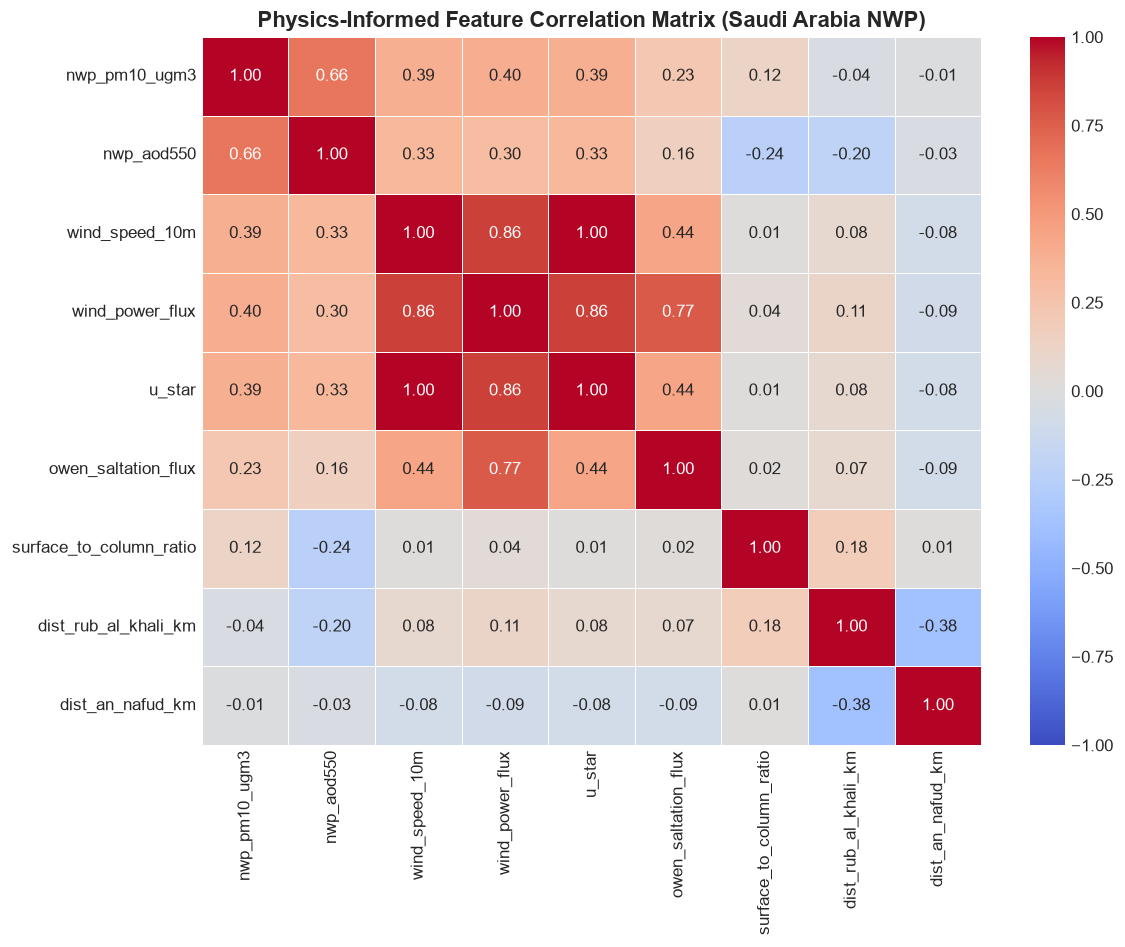

In [7]:
feature_cols = [
    "nwp_pm10_ugm3", "nwp_aod550", "wind_speed_10m", "wind_power_flux",
    "u_star", "owen_saltation_flux", "surface_to_column_ratio",
    "dist_rub_al_khali_km", "dist_an_nafud_km"
]

corr_matrix = df_features[feature_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Physics-Informed Feature Correlation Matrix (Saudi Arabia NWP)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 7.0 Processed Feature Matrix Export
We export the final clean, engineered tabular dataset to `data/processed/saudi_nwp_engineered_features.parquet` ready for model ingestion.


In [8]:
out_dir = Path("../data/processed")
if not out_dir.exists():
    out_dir = Path("data/processed")
out_dir.mkdir(parents=True, exist_ok=True)

parquet_path = out_dir / "saudi_nwp_engineered_features.parquet"
csv_path = out_dir / "saudi_nwp_engineered_features.csv"

# Save to Parquet (fast & compressed) and CSV
df_features.to_parquet(parquet_path, index=False)
df_features.sample(n=min(5000, len(df_features)), random_state=42).to_csv(csv_path, index=False)

print("=" * 70)
print("🎉 FEATURE ENGINEERING PIPELINE COMPLETE!")
print("=" * 70)
print(f"Total Rows:     {len(df_features):,}")
print(f"Total Features: {df_features.shape[1]}")
print(f"Saved Parquet:  {parquet_path} ({parquet_path.stat().st_size / 1e6:.2f} MB)")
print(f"Saved Sample:   {csv_path} ({csv_path.stat().st_size / 1e6:.2f} MB)")
print("Ready for Line A LightGBM & Line B PINN training!")
print("=" * 70)


🎉 FEATURE ENGINEERING PIPELINE COMPLETE!
Total Rows:     130,032
Total Features: 29
Saved Parquet:  ..\data\processed\saudi_nwp_engineered_features.parquet (11.46 MB)
Saved Sample:   ..\data\processed\saudi_nwp_engineered_features.csv (1.77 MB)
Ready for Line A LightGBM & Line B PINN training!
